# Votre premier réseau de neurones
**ÉNONCÉ** · durée estimée : une demi-journée

## 🧭 Où vous allez
Vous allez construire un réseau de neurones qui **retrouve le thème d'un texte**, puis le comparer à des méthodes simples.

## Un réseau de neurones, en trois idées
1. **C'est un modèle comme un autre** : il reçoit des nombres et prédit une classe.
2. **Il apprend par essais corrigés** : il commence avec des réglages tirés au hasard (les **poids**), se trompe, mesure son erreur (la **perte**), et ajuste ses poids pour se tromper un peu moins. Il recommence des milliers de fois.
3. **Il lit les données par paquets** : un **epoch** est un passage complet sur tous les textes d'apprentissage ; un **batch** est le paquet de textes traités avant chaque ajustement.

## Comment travailler
- Chaque cellule fait **une seule chose**. Lisez le commentaire de chaque ligne avant de l'exécuter (`Maj + Entrée`).
- Les cellules marquées **🎯** contiennent des `___` à remplacer : l'indication est dans le commentaire de la ligne.
- Après une cellule, une zone **« Ce que vous devez voir »** décrit le résultat attendu : comparez avec votre écran.
- Il n'y a **aucune fonction à écrire** et aucune vérification automatique : c'est **vous** qui comparez, et les **questions écrites** montrent ce que vous avez compris.

`pip install pandas scikit-learn matplotlib tensorflow`

## Étape 1 — Importer les outils

In [4]:
pip install pandas scikit-learn matplotlib tensorflow

  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 5.6 MB/s  0:00:00m 5.8 MB/s eta 0:00:01
Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1

In [5]:
import numpy as np                                            # calculs sur des tableaux de nombres
import pandas as pd                                           # tableaux de données (comme une table SQL)
import matplotlib.pyplot as plt                               # dessiner des graphiques
from sklearn.model_selection import train_test_split          # découper les données en deux jeux
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer du texte en nombres
from sklearn.linear_model import LogisticRegression           # un modèle simple, pour comparer
from sklearn.metrics import confusion_matrix                  # compter les erreurs du modèle
from tensorflow import keras                                  # la bibliothèque de deep learning
from tensorflow.keras import layers                           # les couches de neurones
keras.utils.set_random_seed(42)                               # fixe le hasard : tout le monde obtient les mêmes résultats

I0000 00:00:1792100642.200157   54688 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792100642.520965   54688 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792100644.103408   54688 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


**Ce que vous devez voir :** rien, ou quelques messages d'avertissement de TensorFlow (sans importance).

## Étape — Charger le corpus
On lit le fichier de textes. **Si vous avez fait le TP A**, remplacez `corpus_secours.csv` par `corpus.csv`.

In [6]:
corpus = pd.read_csv("corpus.csv")           # lit le fichier CSV
print(corpus.shape)                          # (nombre de lignes, nombre de colonnes)
corpus.head()                                # affiche les 5 premières lignes

(239, 4)


,classe,titre,texte,lien
0,astronomie,Glossary of astronomy,This glossary of astronomy is a list of defini...,/wiki/Glossary_of_astronomy
1,astronomie,Outline of astronomy,"Astronomy – studies the universe beyond Earth,...",/wiki/Outline_of_astronomy
2,astronomie,96P sungrazer family,The 96P sungrazer family is a small group of s...,/wiki/96P_sungrazer_family
3,astronomie,Alaknanda Galaxy,The Alaknanda Galaxy (designated as UNCOVER DR...,/wiki/Alaknanda_Galaxy
4,astronomie,Andean dark constellations,Andean dark constellations (Quechua:yana phuyu...,/wiki/Andean_dark_constellations


In [7]:
print(corpus["classe"].value_counts())   # combien de textes dans chaque classe ?

classe
astronomie    60
cuisine       60
football      60
peinture      59
Name: count, dtype: int64


## Étape — Les classes en nombres
Un réseau ne manipule que des **nombres**. On remplace chaque nom de classe par un numéro : 0, 1, 2…

In [8]:
corpus["y"], noms = pd.factorize(corpus["classe"])   # y = le numéro de la classe de chaque texte
print(noms)                                           # la correspondance : la position dans la liste = le numéro
n_classes = len(noms)                                 # le nombre de classes à reconnaître
print("Nombre de classes :", n_classes)

Index(['astronomie', 'cuisine', 'peinture', 'football'], dtype='str')
Nombre de classes : 4


## Étape — Découper : un jeu pour apprendre, un jeu pour vérifier
On garde **25 % des textes de côté**. Le réseau ne les verra **jamais** pendant son apprentissage : c'est notre examen final.

In [9]:
train, test = train_test_split(corpus, test_size=0.25, stratify=corpus["y"], random_state=42)
print("Textes pour apprendre :", len(train))
print("Textes pour vérifier  :", len(test))

Textes pour apprendre : 179
Textes pour vérifier  : 60


## Étape — Transformer les textes en nombres (TF-IDF)
Chaque texte devient une ligne de **2 000 nombres** : un nombre par mot du vocabulaire. Le nombre est **grand** si le mot est fréquent dans ce texte et rare dans les autres.

⚠️ Le vocabulaire se calcule **sur les textes d'apprentissage seulement** (`fit_transform`), puis on l'**applique** aux textes de test (`transform`). Sinon le test « souffle » des informations au modèle.

In [10]:
vectoriseur = TfidfVectorizer(max_features=2000, stop_words="english")   # on garde les 2000 mots les plus utiles
X_train = vectoriseur.fit_transform(train["texte"])    # apprend le vocabulaire ET transforme les textes d'apprentissage
X_test = vectoriseur.transform(test["texte"])          # applique le même vocabulaire aux textes de test
X_train = X_train.toarray().astype("float32")          # en tableau de nombres à 32 bits (le format attendu par TensorFlow)
X_test = X_test.toarray().astype("float32")
y_train = train["y"].values                            # la bonne réponse de chaque texte d'apprentissage
y_test = test["y"].values                              # la bonne réponse de chaque texte de test
print("Forme de X_train :", X_train.shape, "(textes, mots)")

Forme de X_train : (179, 2000) (textes, mots)


**Ce que vous devez voir :** `Forme de X_train : (2250, 2000)` si vous utilisez le corpus de secours (3 000 textes). Avec votre propre corpus, le premier nombre sera plus petit.

## Étape — Regarder ce que « voit » le réseau
Le réseau ne verra jamais les mots, seulement des nombres. Voici les **8 mots qui pèsent le plus** dans le premier texte d'apprentissage.

In [11]:
mots = vectoriseur.get_feature_names_out()   # le mot de chaque colonne
poids = X_train[0]                              # les 2000 nombres du premier texte
positions = np.argsort(poids)                   # les positions des colonnes, rangées du plus petit au plus grand poids
meilleures = positions[-8:]                     # les 8 dernières : les 8 plus grands poids
for i in meilleures:                            # pour chacune de ces 8 positions...
    print(mots[i], round(poids[i], 3))          # ...on affiche le mot et son poids

fueled 0.173
fuel 0.173
feed 0.173
pellets 0.346
pellet 0.346
grills 0.346
smokers 0.346
grill 0.346


## Étape — Deux références à battre
Avant de construire un réseau, on regarde ce que font **deux méthodes très simples**. **Si le réseau ne fait pas mieux, il ne sert à rien.**

In [14]:
classe_frequente = np.bincount(y_train).argmax()          # la classe qui revient le plus souvent dans l'apprentissage
precision_hasard = np.mean(y_test == classe_frequente)  # part de bonnes réponses si on répond toujours celle-là
print("Toujours la même réponse :", round(precision_hasard, 3))

Toujours la même réponse : 0.25


In [15]:
logistique = LogisticRegression(max_iter=2000)      # un modèle simple
logistique.fit(X_train, y_train)                       # il apprend sur les textes d'apprentissage
precision_logistique = logistique.score(X_test, y_test)   # sa part de bonnes réponses sur les textes de test
print("Régression logistique :", round(precision_logistique, 3))

Régression logistique : 0.967


**Ce que vous devez voir :** « toujours la même réponse » autour de `0.333` (3 classes équilibrées) et la régression logistique **bien au-dessus** (autour de `0.85` avec le corpus de secours).

## 🎯 Étape — Construire le réseau
Schéma : **2 000 nombres en entrée → 64 neurones → 32 neurones → une probabilité par classe**.

- `layers.Dense(64, activation="relu")` : une couche de **64 neurones**. `relu` garde les valeurs positives et met les négatives à zéro.
- La **dernière couche** a **un neurone par classe** et l'activation `softmax` : elle donne **une probabilité par classe**, qui totalisent 1.

**À compléter :** remplacez les trois `___` (64, puis 32, puis le nombre de classes).

In [18]:
nb_mots = X_train.shape[1]                          # nombre d'entrées : un nombre par mot du vocabulaire
reseau = keras.Sequential()                         # un réseau vide, dans lequel on empile des couches
reseau.add(layers.Input(shape=(nb_mots,)))          # l'entrée : nb_mots nombres par texte
reseau.add(layers.Dense(64, activation="relu"))    # 1re couche cachée : 64 neurones
reseau.add(layers.Dense(32, activation="relu"))    # 2e couche cachée : 32 neurones
reseau.add(layers.Dense(n_classes, activation="softmax"))   # sortie : un neurone par classe (variable n_classes)

E0000 00:00:1792101193.200629   54688 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Maintenant on **compile** : on dit au réseau comment mesurer son erreur et comment s'ajuster.

- `loss="sparse_categorical_crossentropy"` : la **perte**. Elle punit surtout les réponses **sûres et fausses**.
- `optimizer="adam"` : la méthode qui **ajuste les poids** pour réduire la perte.
- `metrics=["accuracy"]` : la part de bonnes réponses, qu'on suit en plus.

In [19]:
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
reseau.summary()                                     # affiche les couches et le nombre de paramètres

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,276 (508.89 KB)

 Trainable params: 130,276 (508.89 KB)

 Non-trainable params: 0 (0.00 B)

**Ce que vous devez voir :** un tableau de 3 couches `Dense`, avec **130 243 paramètres** en tout (corpus de secours). Un **paramètre** est un nombre que le réseau va ajuster.

### ✍️ Question
**Retrouvez à la main le nombre de paramètres de la première couche (64 neurones) : chaque neurone a un poids par mot du vocabulaire, plus 1 biais. Vérifiez avec le tableau.**

*Votre réponse :*

> 2000+1 =2001. 2001 X 64 = 128 064

## 🎯 Étape — Entraîner
- `validation_split=0.2` met de côté **20 % des textes d'apprentissage** : à chaque epoch, on mesure l'erreur sur ces textes que le réseau n'utilise **pas** pour s'ajuster. C'est notre détecteur de « mémorisation ».

**À compléter :** `epochs` vaut **20** et `batch_size` vaut **32**.

In [21]:
histoire = reseau.fit(X_train, y_train,                # on donne les textes et leurs bonnes réponses
                    validation_split=0.2,                   # 20 % des textes servent à surveiller l'apprentissage
                    epochs=20,                          # nombre de passages complets sur les textes
                    batch_size=32,                      # nombre de textes traités avant chaque ajustement
                    verbose=0)                              # 0 = pas d'affichage pendant l'entraînement
print("Entraînement terminé")

Entraînement terminé


## Étape — Lire les courbes
Deux courbes par graphique : l'erreur sur les textes d'**apprentissage** et sur les textes de **validation**.

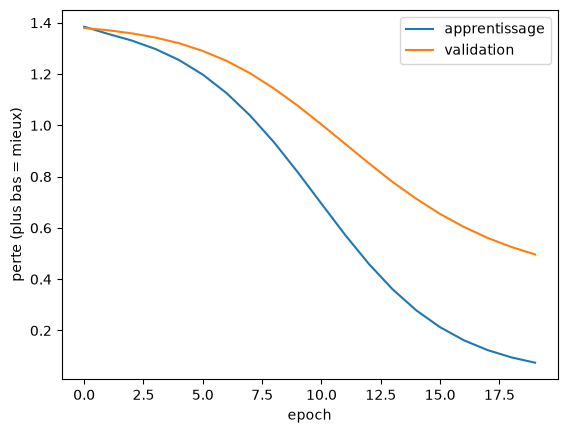

In [22]:
plt.plot(histoire.history["loss"], label="apprentissage")    # perte sur les textes d'apprentissage, epoch après epoch
plt.plot(histoire.history["val_loss"], label="validation")   # perte sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("perte (plus bas = mieux)")
plt.legend()
plt.show()

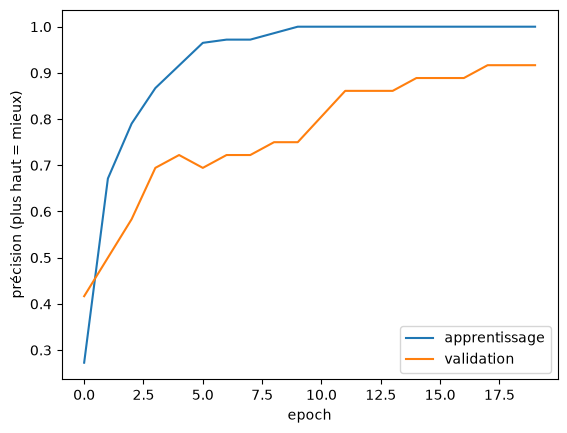

In [23]:
plt.plot(histoire.history["accuracy"], label="apprentissage")   # précision sur les textes d'apprentissage
plt.plot(histoire.history["val_accuracy"], label="validation")  # précision sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("précision (plus haut = mieux)")
plt.legend()
plt.show()

**Comment lire :** si les deux courbes **baissent ensemble**, le réseau apprend quelque chose de général. Si celle d'apprentissage continue de baisser alors que celle de validation **remonte**, le réseau **mémorise** (surapprentissage).

### ✍️ Question
**À partir de quel epoch environ la courbe de validation cesse-t-elle de s'améliorer ?**

*Votre réponse :*

> La performance sur les données de validation atteint son plateau optimal et cesse de s'améliorer significativement autour de l'epoch 17

## 🎯 Étape — Évaluer sur les textes de test
C'est **la seule fois** qu'on utilise les textes de test. `predict` donne **une probabilité par classe** pour chaque texte ; la **réponse** du réseau est la classe de **plus forte probabilité** (`argmax`).

**À compléter :** `axis=1` (pour choisir la plus grande probabilité de **chaque ligne**).

In [24]:
probas = reseau.predict(X_test, verbose=0)         # une ligne par texte, une colonne par classe
print("Probabilités du premier texte :", probas[0])   # trois nombres qui totalisent 1
y_pred = np.argmax(probas, axis=1)          # la classe de plus forte probabilité, pour chaque texte
precision_reseau = np.mean(y_pred == y_test)          # part de bonnes réponses
print("Réseau de neurones :", round(precision_reseau, 3))
print("Régression logistique :", round(precision_logistique, 3))
print("Toujours la même réponse :", round(precision_hasard, 3))

Probabilités du premier texte : [0.01999435 0.01386697 0.0398365  0.92630213]
Réseau de neurones : 0.9
Régression logistique : 0.967
Toujours la même réponse : 0.25


## Étape — La matrice de confusion
Pour chaque **vraie classe** (lignes), elle compte ce que le réseau a **répondu** (colonnes). La **diagonale** = les bonnes réponses.

In [25]:
matrice = confusion_matrix(y_test, y_pred)               # compte les réponses du réseau pour chaque vraie classe
tableau = pd.DataFrame(matrice, index=noms, columns=noms)  # on met des noms de classes plutôt que des numéros
print("Lignes = vraie classe | colonnes = réponse du réseau")
tableau

Lignes = vraie classe | colonnes = réponse du réseau


,astronomie,cuisine,peinture,football
astronomie,12,3,0,0
cuisine,1,14,0,0
peinture,0,2,13,0
football,0,0,0,15


### ✍️ Questions
**1. Le réseau bat-il la régression logistique ? De combien ?**
**2. Quelles classes sont le plus souvent confondues, et pourquoi, à votre avis ?**

*Vos réponses :*

> 1. Non, le réseau obtient une précision de $0.9$ tandis que la régression logistique atteint $0.967$. La régression logistique bat donc le réseau de neurones de 0.067 (soit environ 6.7% de précision en plus).
> 2. D'après la matrice de confusion, les classes astronomie et cuisine sont les plus confondues (3 articles d'astronomie classés à tort en cuisine :/ ). Cela peut s'expliquer par la présence de termes communs ou de structures de phrases partagées dans le vocabulaire de ces articles. Ou au fait qu'en rajoutant un G a astronomie on a gastronomie

## 🎯 Étape — Tester trois tailles de réseau
**Plus gros veut-il dire meilleur ?** Prédisez d'abord, puis vérifiez.

La cellule suivante reconstruit et entraîne un réseau avec **deux nombres de neurones que vous choisissez** en haut.

**À faire :** exécutez-la **trois fois**, en changeant les deux nombres à chaque fois : `2` et `2`, puis `64` et `32`, puis `256` et `128`. Notez la précision dans le tableau.

| neurones 1re couche | neurones 2e couche | précision sur le test |
|---|---|---|
| 2 | 2 | |
| 64 | 32 | |
| 256 | 128 | |

In [28]:
neurones1 = 256                    # nombre de neurones de la 1re couche cachée
neurones2 = 128                          # nombre de neurones de la 2e couche cachée

keras.utils.set_random_seed(42)                       # même hasard à chaque essai
essai = keras.Sequential()                            # un réseau vide
essai.add(layers.Input(shape=(nb_mots,)))
essai.add(layers.Dense(neurones1, activation="relu"))
essai.add(layers.Dense(neurones2, activation="relu"))
essai.add(layers.Dense(n_classes, activation="softmax"))
essai.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
essai.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=32, verbose=0)   # entraînement

reponses = np.argmax(essai.predict(X_test, verbose=0), axis=1)   # la réponse du réseau pour chaque texte de test
print(neurones1, "+", neurones2, "neurones | précision :", round(np.mean(reponses == y_test), 3), "| paramètres :", essai.count_params())

256 + 128 neurones | précision : 0.95 | paramètres : 545668


### ✍️ Question
**Un réseau plus gros est-il meilleur ici ? Que remarquez-vous sur le nombre de paramètres ?**

*Votre réponse :*

> Ouiun réseau plus grand (256 et 128 neurones) améliore la précision qui passe à 0.95 (contre 0.9 précédemment), mais on remarque que le nombre de paramètres explose aussi pour atteindre 545 668 paramètres (contre environ 130 000 avant), ce qui augmente fortement le risque de surapprentissage et le coût de calcul pour un gain marginal.

## ✅ Ce qu'il faut retenir
- Un réseau est un modèle qui **apprend en ajustant ses poids** pour réduire une **perte**.
- Pour classer en **N classes** : une sortie à **N neurones** avec `softmax`.
- **Epoch** = un passage complet ; **batch** = le paquet de textes avant chaque ajustement.
- On **compare toujours** à une référence simple, on **lit les courbes**, on regarde la **matrice de confusion**.
- Le vocabulaire se calcule **sur l'apprentissage seul**.